# Host types and price gaps

This notebook combines the regression predictions with the host types and compares advertised prices with the model's estimates. It includes listing-weighted and host-weighted summaries, a check excluding high-priced listings, and a chart of the results.

The main percentage measure uses the model estimate as the denominator. Rankings can change with the measure. Price gaps also reflect the model's limitations and do not prove that a listing is incorrectly priced.

Data version: `1f318105a6914189ed8db9a0f1a9fe67819c35e6`. Run from the repository root or notebooks folder. In Colab, missing inputs are downloaded from that fixed data version and checked by hash.

In [1]:
"""Compare listing price gaps by host type."""

import hashlib
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from urllib.request import urlopen

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/processed"
OUT = ROOT / "reports/tables"
FIGURE = ROOT / "reports/figures/price_gaps_by_host_type.png"
EXPECTED_SHA = "1f318105a6914189ed8db9a0f1a9fe67819c35e6"
INPUT_HASHES = {'predictions.csv': '73388a1c4bf9e6a13550e9aeb65f73a6e7c164b4b06137f05a4d95e545dc2d92', 'host_types.csv': 'faa66aa0fef0da12a85e21f2014d734eafd0db75f313204f01870e942d415d64', 'listings_clean.csv': '1ba52326f0f8a0f76a3a68f34ad62fe066f42b46926f6d9e6be6293011d7b784'}

def load_reviewed_inputs():
    DATA.mkdir(parents=True, exist_ok=True)
    for name, expected in INPUT_HASHES.items():
        target = DATA / name
        if not target.exists():
            url = f"https://raw.githubusercontent.com/aabouraya/airbnb-nyc-pricing-segments/{EXPECTED_SHA}/data/processed/{name}"
            print(f"Loading {name} from data version {EXPECTED_SHA[:8]}")
            with urlopen(url, timeout=60) as response:
                content = response.read()
            if hashlib.sha256(content).hexdigest() != expected:
                raise ValueError(f"Downloaded data hash differs: {name}")
            target.write_bytes(content)
        if hashlib.sha256(target.read_bytes()).hexdigest() != expected:
            raise ValueError(f"Local {name} differs from the reviewed data version. Review the input change before updating this analysis.")



def summarize_listings(frame):
    return frame.groupby(["host_type", "host_type_label"], observed=True).agg(
        listings=("id", "size"),
        hosts=("host_id", "nunique"),
        median_price_usd=("price", "median"),
        median_prediction_usd=("pred_tree", "median"),
        median_signed_gap_usd=("signed_gap_usd", "median"),
        median_absolute_gap_usd=("absolute_gap_usd", "median"),
        median_signed_gap_pct=("signed_gap_pct", "median"),
        median_absolute_gap_pct=("absolute_gap_pct", "median"),
        share_above_estimate=("signed_gap_usd", lambda x: (x > 0).mean()),
        share_below_estimate=("signed_gap_usd", lambda x: (x < 0).mean()),
    ).reset_index()


def summarize_hosts(frame):
    # First summarize each host's listings, then weight those hosts equally.
    per_host = frame.groupby(
        ["host_id", "host_type", "host_type_label"], observed=True
    ).agg(
        host_median_signed_gap_usd=("signed_gap_usd", "median"),
        host_median_absolute_gap_usd=("absolute_gap_usd", "median"),
        host_median_signed_gap_pct=("signed_gap_pct", "median"),
        host_median_absolute_gap_pct=("absolute_gap_pct", "median"),
    ).reset_index()
    return per_host.groupby(["host_type", "host_type_label"], observed=True).agg(
        hosts=("host_id", "size"),
        median_of_host_signed_gap_usd=("host_median_signed_gap_usd", "median"),
        median_of_host_absolute_gap_usd=("host_median_absolute_gap_usd", "median"),
        median_of_host_signed_gap_pct=("host_median_signed_gap_pct", "median"),
        median_of_host_absolute_gap_pct=("host_median_absolute_gap_pct", "median"),
    ).reset_index()


def run():
    load_reviewed_inputs()
    predictions = pd.read_csv(DATA / "predictions.csv")
    types = pd.read_csv(DATA / "host_types.csv")
    listings = pd.read_csv(DATA / "listings_clean.csv")
    if predictions["id"].duplicated().any() or types["host_id"].duplicated().any():
        raise ValueError("Duplicate handover keys would invalidate the join.")
    if listings["id"].duplicated().any():
        raise ValueError("Duplicate cleaned-listing identifiers.")
    if set(predictions["id"]) != set(listings["id"]) or len(predictions) != 48870:
        raise ValueError("Predictions do not cover the expected cleaned-listing population.")
    metadata = predictions[["id", "host_id", "price"]].merge(
        listings[["id", "host_id", "price"]], on="id", validate="one_to_one",
        suffixes=("_prediction", "_clean"),
    )
    if not metadata["host_id_prediction"].equals(metadata["host_id_clean"]):
        raise ValueError("Host identifiers differ between handovers.")
    if not np.allclose(metadata["price_prediction"], metadata["price_clean"]):
        raise ValueError("Actual prices differ between handovers.")
    values = predictions[["price", "pred_baseline", "pred_linear", "pred_tree"]]
    if not np.isfinite(values.to_numpy()).all() or (values <= 0).any().any():
        raise ValueError("Gap calculations require finite positive prices and predictions.")
    if predictions.groupby("host_id")["fold"].nunique().gt(1).any():
        raise ValueError("A host occurs in multiple prediction folds.")

    joined = predictions.merge(types, on="host_id", how="left", validate="many_to_one")
    if len(joined) != 48870 or joined["host_type"].isna().any():
        raise ValueError("Host-type join lost, duplicated or failed to match listings.")
    joined["host_type"] = joined["host_type"].astype(int)
    joined["signed_gap_usd"] = joined["price"] - joined["pred_tree"]
    joined["absolute_gap_usd"] = joined["signed_gap_usd"].abs()
    joined["signed_gap_pct"] = 100 * joined["signed_gap_usd"] / joined["pred_tree"]
    joined["absolute_gap_pct"] = joined["signed_gap_pct"].abs()

    OUT.mkdir(parents=True, exist_ok=True)
    FIGURE.parent.mkdir(parents=True, exist_ok=True)
    joined.to_csv(DATA / "price_gaps.csv", index=False)
    all_listing = summarize_listings(joined)
    retained = joined.loc[joined["price"] <= 1000].copy()
    no_high_listing = summarize_listings(retained)
    all_host = summarize_hosts(joined)
    no_high_host = summarize_hosts(retained)
    for name, table in [
        ("price_gap_summary.csv", all_listing),
        ("price_gap_summary_without_high_prices.csv", no_high_listing),
        ("host_weighted_price_gaps.csv", all_host),
        ("host_weighted_without_high_prices.csv", no_high_host),
    ]:
        table.to_csv(OUT / name, index=False)

    sensitivity = all_listing.merge(
        no_high_listing, on=["host_type", "host_type_label"],
        suffixes=("_all", "_without_high"), validate="one_to_one",
    )
    sensitivity["rank_absolute_pct_all"] = sensitivity["median_absolute_gap_pct_all"].rank(
        ascending=False, method="min"
    )
    sensitivity["rank_absolute_pct_without_high"] = sensitivity[
        "median_absolute_gap_pct_without_high"
    ].rank(ascending=False, method="min")
    sensitivity.to_csv(OUT / "price_gap_sensitivity.csv", index=False)

    order = all_listing.sort_values("median_absolute_gap_pct")["host_type"].tolist()
    full = all_listing.set_index("host_type").loc[order]
    trimmed = no_high_listing.set_index("host_type").loc[order]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    y = np.arange(len(order))
    for ax, column, label in [
        (axes[0], "median_signed_gap_pct", "Median signed gap (% of model estimate)"),
        (axes[1], "median_absolute_gap_pct", "Median absolute gap (% of model estimate)"),
    ]:
        ax.scatter(full[column], y + .09, color="#2a78d6", label="All retained listings")
        ax.scatter(trimmed[column], y - .09, color="#eb6834", marker="x",
                   label="Actual price at most USD 1,000")
        ax.axvline(0, color="#777777", linewidth=.7)
        ax.set_xlabel(label)
        ax.grid(axis="x", alpha=.2)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_yticks(y, full["host_type_label"])
    axes[1].legend(loc="upper left", fontsize=8)
    fig.suptitle("Price gaps by host type: descriptive, listing-weighted")
    fig.text(.5, .01, "Positive = advertised above prediction; not proof of mispricing. "
             "NYC Airbnb 2019. Source: Group A analysis.", ha="center", fontsize=8)
    fig.tight_layout(rect=(0, .04, 1, 1))
    fig.savefig(FIGURE, dpi=180)
    plt.close(fig)

    metrics = {
        "source_sha": EXPECTED_SHA,
        "analysis_scope": "Descriptive NYC 2019 host-type and price-gap comparison",
        "rows": len(joined), "hosts_in_join": int(joined["host_id"].nunique()),
        "excluded_high_price_listings": int((joined["price"] > 1000).sum()),
        "remaining_without_high_prices": len(retained),
        "formula_usd": "advertised price - out-of-fold pred_tree",
        "formula_pct": "100 * (advertised price - out-of-fold pred_tree) / out-of-fold pred_tree",
        "primary_weighting": "One observation per retained listing",
        "alternative_weighting": "Median within each host, then median across equally weighted hosts",
        "rank_order_stable_without_high_prices": (
            all_listing.sort_values("median_absolute_gap_pct", ascending=False)["host_type"].tolist()
            == no_high_listing.sort_values("median_absolute_gap_pct", ascending=False)["host_type"].tolist()
        ),
        "listing_results": all_listing.round(6).to_dict(orient="records"),
        "host_results": all_host.round(6).to_dict(orient="records"),
        "sensitivity_results": sensitivity.round(6).to_dict(orient="records"),
        "limits": [
            "Descriptive in this 2019 snapshot, not causal or proof of mispricing.",
            "Clusters are descriptive; no independent confirmatory test of between-type gaps.",
            "Typical percentage and dollar gaps answer different questions; both supplied.",
            "The 30% diagnostic is not justified as an action threshold.",
            "Removing high-priced listings changes the observed population, not a model retraining.",
        ],
    }
    (OUT / "analysis-results.json").write_text(json.dumps(metrics, indent=2))
    print(all_listing[["host_type", "host_type_label", "listings",
                       "median_signed_gap_pct", "median_absolute_gap_pct",
                       "median_absolute_gap_usd"]].round(2).to_string(index=False))
    print("Rows:", len(joined), "| Excluded actual prices above USD 1,000:", len(joined)-len(retained))
    print("Full relative-gap ranking unchanged in sensitivity:",
          metrics["rank_order_stable_without_high_prices"])
    return metrics




results = run()


 host_type                         host_type_label  listings  median_signed_gap_pct  median_absolute_gap_pct  median_absolute_gap_usd
         0              One room, low availability      9799                  -6.22                    23.08                    16.81
         1       One entire home, low availability     12891                  -9.86                    25.56                    42.12
         2 Several listings, open most of the year      7942                   0.24                    24.81                    22.03
         3  One entire home, open most of the year      4813                  10.68                    28.15                    42.53
         4            2 to 3 listings, rarely open      6763                  -2.25                    22.87                    19.05
         5            Long stays (2 weeks or more)      3393                  -4.37                    25.41                    26.93
         6         One room, open most of the year      3269  

## Summary tables

,host_type,host_type_label,listings,hosts,median_price_usd,median_prediction_usd,median_signed_gap_usd,median_absolute_gap_usd,median_signed_gap_pct,median_absolute_gap_pct,share_above_estimate,share_below_estimate
0,0,"One room, low availability",9799,9799,70.0,70.14,-4.67,16.81,-6.22,23.08,0.43,0.57
1,1,"One entire home, low availability",12891,12891,150.0,172.38,-16.19,42.12,-9.86,25.56,0.39,0.61
2,2,"Several listings, open most of the year",7942,1189,99.0,93.78,0.20,22.03,0.24,24.81,0.50,0.50
3,3,"One entire home, open most of the year",4813,4539,180.0,160.47,16.59,42.53,10.68,28.15,0.60,0.40
4,4,"2 to 3 listings, rarely open",6763,3036,85.0,82.47,-1.87,19.05,-2.25,22.87,0.47,0.53
5,5,Long stays (2 weeks or more),3393,3077,110.0,118.69,-3.98,26.93,-4.37,25.41,0.45,0.55
6,6,"One room, open most of the year",3269,2911,75.0,65.51,6.70,16.10,9.80,23.89,0.61,0.39


,host_type,host_type_label,hosts,median_of_host_signed_gap_usd,median_of_host_absolute_gap_usd,median_of_host_signed_gap_pct,median_of_host_absolute_gap_pct
0,0,"One room, low availability",9799,-4.67,16.81,-6.22,23.08
1,1,"One entire home, low availability",12891,-16.19,42.12,-9.86,25.56
2,2,"Several listings, open most of the year",1189,0.65,17.99,0.91,23.88
3,3,"One entire home, open most of the year",4539,16.76,43.59,10.80,28.30
4,4,"2 to 3 listings, rarely open",3036,-0.72,21.00,-0.45,23.65
5,5,Long stays (2 weeks or more),3077,-4.37,27.10,-4.83,25.63
6,6,"One room, open most of the year",2911,6.88,16.42,10.08,24.38


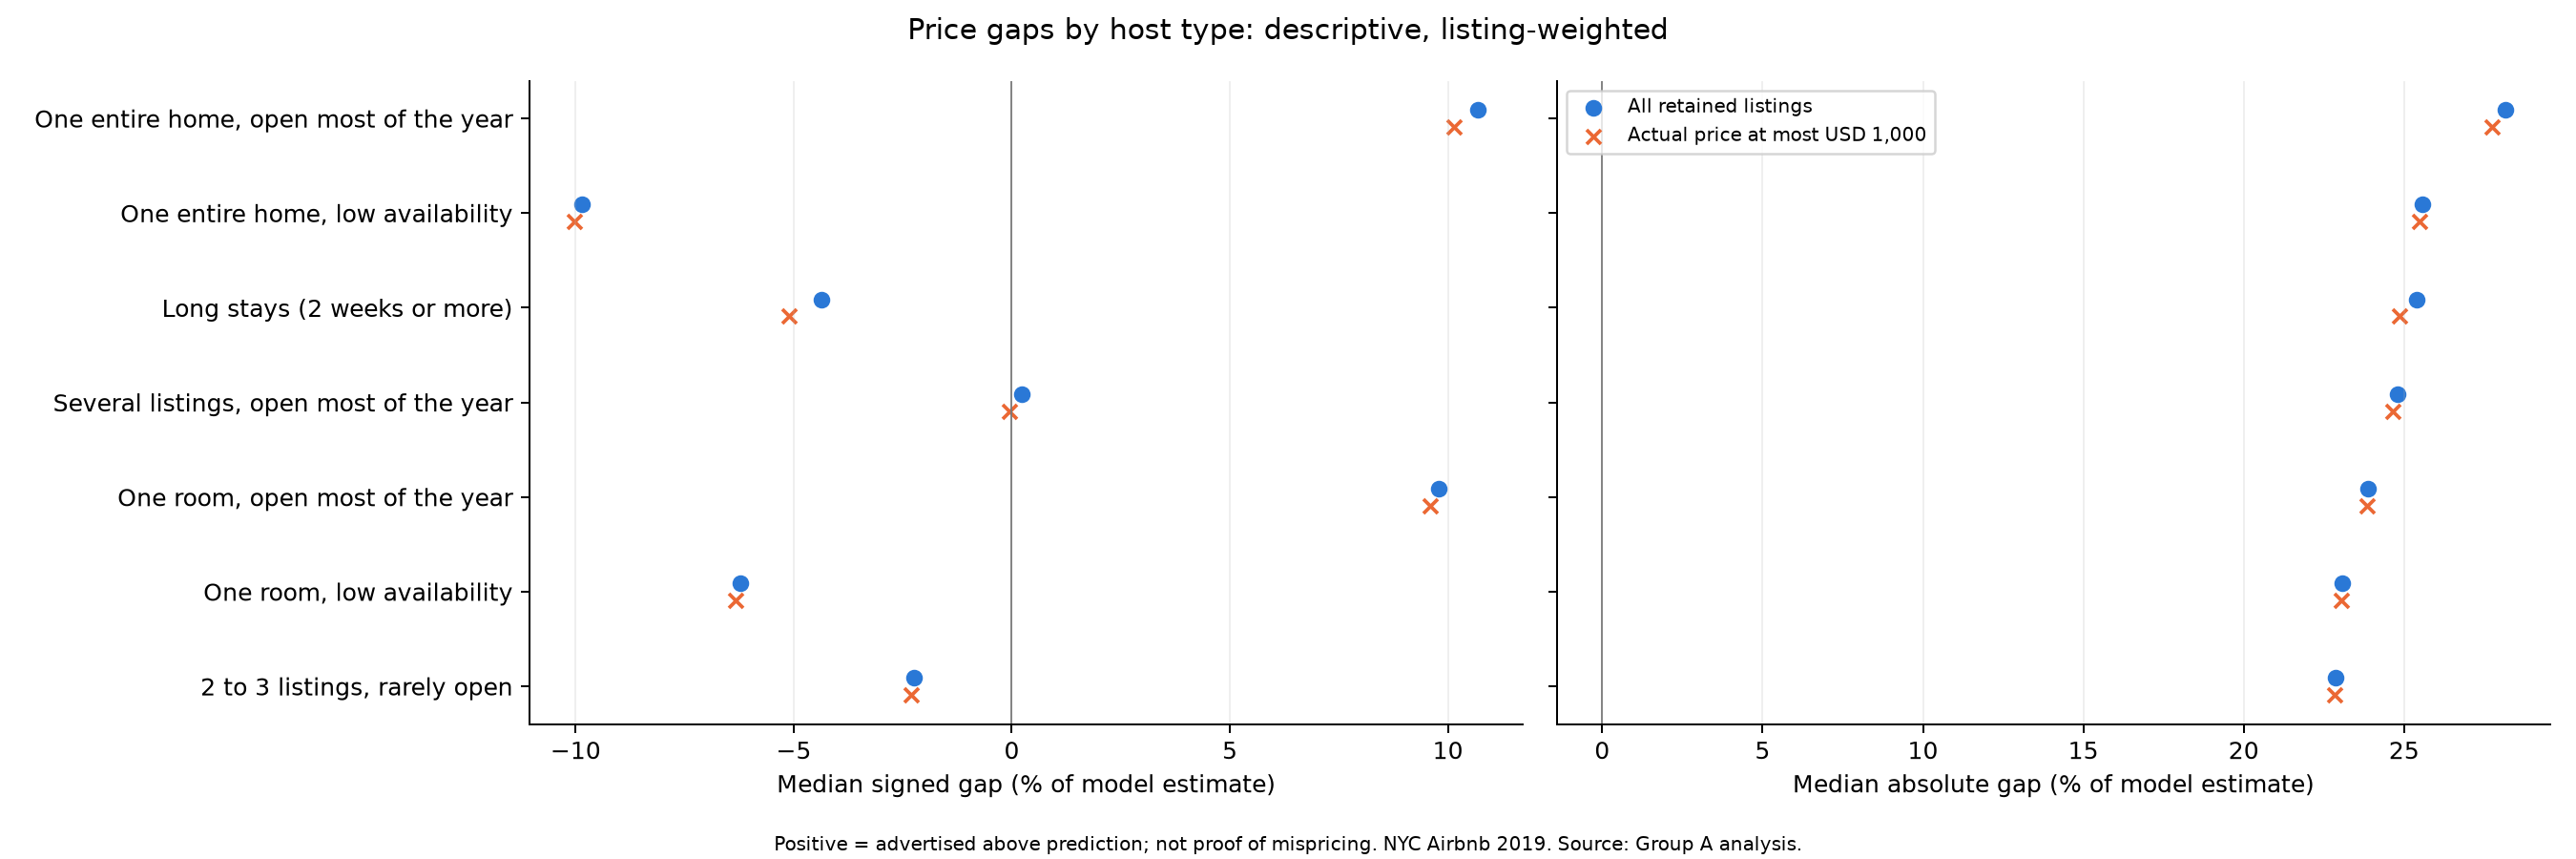

In [2]:
from IPython.display import display, Image
display(pd.read_csv(OUT / "price_gap_summary.csv").round(2))
display(pd.read_csv(OUT / "host_weighted_price_gaps.csv").round(2))
display(Image(filename=str(FIGURE)))


## Metric and validation-fold checks

In [3]:

comparison = pd.read_csv(DATA / "price_gaps.csv")
denominator_rows = []
for type_id, group in comparison.groupby("host_type"):
    denominator_rows.append({
        "host_type": type_id,
        "host_type_label": group["host_type_label"].iloc[0],
        "median_absolute_gap_pct_of_prediction": np.median(100 * np.abs(group["price"] - group["pred_tree"]) / group["pred_tree"]),
        "median_absolute_gap_pct_of_advertised_price": np.median(100 * np.abs(group["price"] - group["pred_tree"]) / group["price"]),
    })
denominator_check = pd.DataFrame(denominator_rows)
display(denominator_check.round(2))

fold_rows = []
for fold, subset in comparison.groupby("fold"):
    per_type = subset.groupby("host_type")["absolute_gap_pct"].median()
    fold_rows.append({"fold": fold, "largest_gap_host_type": int(per_type.idxmax()),
                      "median_absolute_gap_pct": per_type.max()})
display(pd.DataFrame(fold_rows).round(2))

model_rows = []
for model in ["pred_baseline", "pred_linear", "pred_tree"]:
    candidate = comparison.assign(gap=100 * np.abs(comparison["price"] - comparison[model]) / comparison[model])
    medians = candidate.groupby("host_type")["gap"].median()
    leaders = medians.index[np.isclose(medians, medians.max())].tolist()
    model_rows.append({"prediction": model, "largest_gap_host_types": str(leaders),
                       "median_absolute_gap_pct": medians.max()})
display(pd.DataFrame(model_rows).round(2))
print("Advertised price range:", comparison["price"].min(), comparison["price"].max())
print("Tree prediction range:", comparison["pred_tree"].min(), comparison["pred_tree"].max())


,host_type,host_type_label,median_absolute_gap_pct_of_prediction,median_absolute_gap_pct_of_advertised_price
0,0,"One room, low availability",23.08,24.63
1,1,"One entire home, low availability",25.56,27.96
2,2,"Several listings, open most of the year",24.81,25.18
3,3,"One entire home, open most of the year",28.15,27.73
4,4,"2 to 3 listings, rarely open",22.87,23.09
5,5,Long stays (2 weeks or more),25.41,26.97
6,6,"One room, open most of the year",23.89,23.30


,fold,largest_gap_host_type,median_absolute_gap_pct
0,0,3,27.71
1,1,3,28.67
2,2,3,27.27
3,3,3,28.90
4,4,3,27.44


,prediction,largest_gap_host_types,median_absolute_gap_pct
0,pred_baseline,"[3, 5]",31.03
1,pred_linear,[3],29.23
2,pred_tree,[3],28.15


Advertised price range: 10 10000
Tree prediction range: 26.274693491324328 499.3696813265011


## Interpretation

Percentage gaps in the main comparison use the model estimate as the denominator. The order of the two entire-home groups reverses when advertised price is used instead. The main leading group remains first across all five prediction folds; the baseline has a tie. Predictions cover a narrower price range than advertisements. Gaps therefore include model error and unobserved property differences, not proof of incorrect pricing. Use the comparison to guide further pricing checks, not automatic changes.